# Assignment 08: Grouped Summaries of an Imaging Network

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import pyarrow

print("pandas:", pd.__version__)
print("pyarrow:", pyarrow.__version__)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

MISSING_PATH = OUTPUT_DIR / "missing_by_modality.csv"
SITE_SUMMARY_PATH = OUTPUT_DIR / "site_summary.csv"
SITE_MODALITY_PATH = OUTPUT_DIR / "site_modality_summary.csv"
DELAYED_STAT_PATH = OUTPUT_DIR / "delayed_stat_exams.csv"
CT_DOSE_PATH = OUTPUT_DIR / "ct_dose_review.csv"
SLOWEST_PATH = OUTPUT_DIR / "slowest_stat_reports.csv"
PIVOT_PATH = OUTPUT_DIR / "median_report_pivot.csv"
PAIRPLOT_PNG = OUTPUT_DIR / "pairplot.png"  # seaborn route
PAIRPLOT_HTML = OUTPUT_DIR / "pairplot.html"  # Altair route: one of these two
PAIRPLOT_JSON = OUTPUT_DIR / "pairplot.json"

pandas: 3.0.5
pyarrow: 25.0.0


## Load the data

This cell downloads the exam log from the course repository when `data/` lacks it (`urlretrieve(url, path)` saves the file at a web address to `path`), then reads it: one row per exam. Run it as it is.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/christopherseaman/datasci_217/main/08/assignment/data"
DATA_FILES = ["imaging_exams.parquet"]

DATA_DIR.mkdir(exist_ok=True)
for name in DATA_FILES:
    if not (DATA_DIR / name).exists():
        print("downloading", name)
        urlretrieve(f"{DATA_URL}/{name}", DATA_DIR / name)

exams = pd.read_parquet(DATA_DIR / "imaging_exams.parquet")
print("exams:", exams.shape)
exams.head()

exams: (540228, 15)


,exam_id,patient_id,site,exam_date,age,sex,setting,priority,modality,body_region,scan_min,dose_msv,wait_hr,report_hr,reader_id
0,E0000001,P077750,Northgate,2025-01-01,67,M,Inpatient,Routine,Ultrasound,Abdomen/Pelvis,28,NaN,43.3,11.12,T04
1,E0000002,P164273,Downtown,2025-01-01,75,M,Inpatient,Urgent,MRI,Extremity,51,NaN,9.0,1.75,T01
2,E0000003,P198046,Northgate,2025-01-01,70,M,Inpatient,STAT,CT,Head,12,2.188,2.6,2.11,T02
3,E0000004,P134356,Northgate,2025-01-01,50,F,ED,STAT,X-ray,Chest,7,0.023,0.5,NaN,T02
4,E0000005,P054587,Harbor,2025-01-01,7,M,ED,Urgent,X-ray,Spine,7,0.404,12.1,4.16,T02


## Task 1: Explore the log and summarize each site

### 1.1 Explore the exam log

> **Checkpoint: `output/pairplot.png`, or `output/pairplot.html` or `.json`**
> One pairplot of all five numeric columns, from seaborn or Altair.

> **Checkpoint: `output/missing_by_modality.csv`**
> Four rows, `CT` to `X-ray`, under the header `modality,report_hr,dose_msv`.

In [3]:
distinct_exams = exams["exam_id"].nunique()
patients = exams["patient_id"].nunique()
print("rows:", len(exams))
print("distinct exams:", distinct_exams)
print("patients:", patients)

display(exams.info())
display(exams.describe())

rows: 540228
distinct exams: 540228
patients: 210000
<class 'pandas.DataFrame'>
RangeIndex: 540228 entries, 0 to 540227
Data columns (total 15 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   exam_id      540228 non-null  str           
 1   patient_id   540228 non-null  str           
 2   site         540228 non-null  str           
 3   exam_date    540228 non-null  datetime64[ms]
 4   age          540228 non-null  int64         
 5   sex          540228 non-null  str           
 6   setting      540228 non-null  str           
 7   priority     540228 non-null  str           
 8   modality     540228 non-null  str           
 9   body_region  540228 non-null  str           
 10  scan_min     540228 non-null  int64         
 11  dose_msv     347619 non-null  float64       
 12  wait_hr      540228 non-null  float64       
 13  report_hr    537966 non-null  float64       
 14  reader_id    540228 non-null  str         

None

,exam_date,age,scan_min,dose_msv,wait_hr,report_hr
count,540228,540228.000000,540228.000000,347619.000000,540228.000000,537966.000000
mean,2025-07-01 00:51:55.804000,56.140002,17.933854,2.522546,82.990732,9.562691
min,2025-01-01 00:00:00,1.000000,2.000000,0.000000,0.100000,0.050000
25%,2025-03-29 00:00:00,45.000000,8.000000,0.013000,1.500000,0.990000
50%,2025-06-30 00:00:00,58.000000,12.000000,0.031000,19.600000,5.640000
75%,2025-10-03 00:00:00,71.000000,24.000000,2.584000,96.100000,13.100000
max,2025-12-31 00:00:00,97.000000,153.000000,46.512000,4058.200000,252.500000
std,NaN,21.466531,13.426752,4.351553,156.082523,11.984275


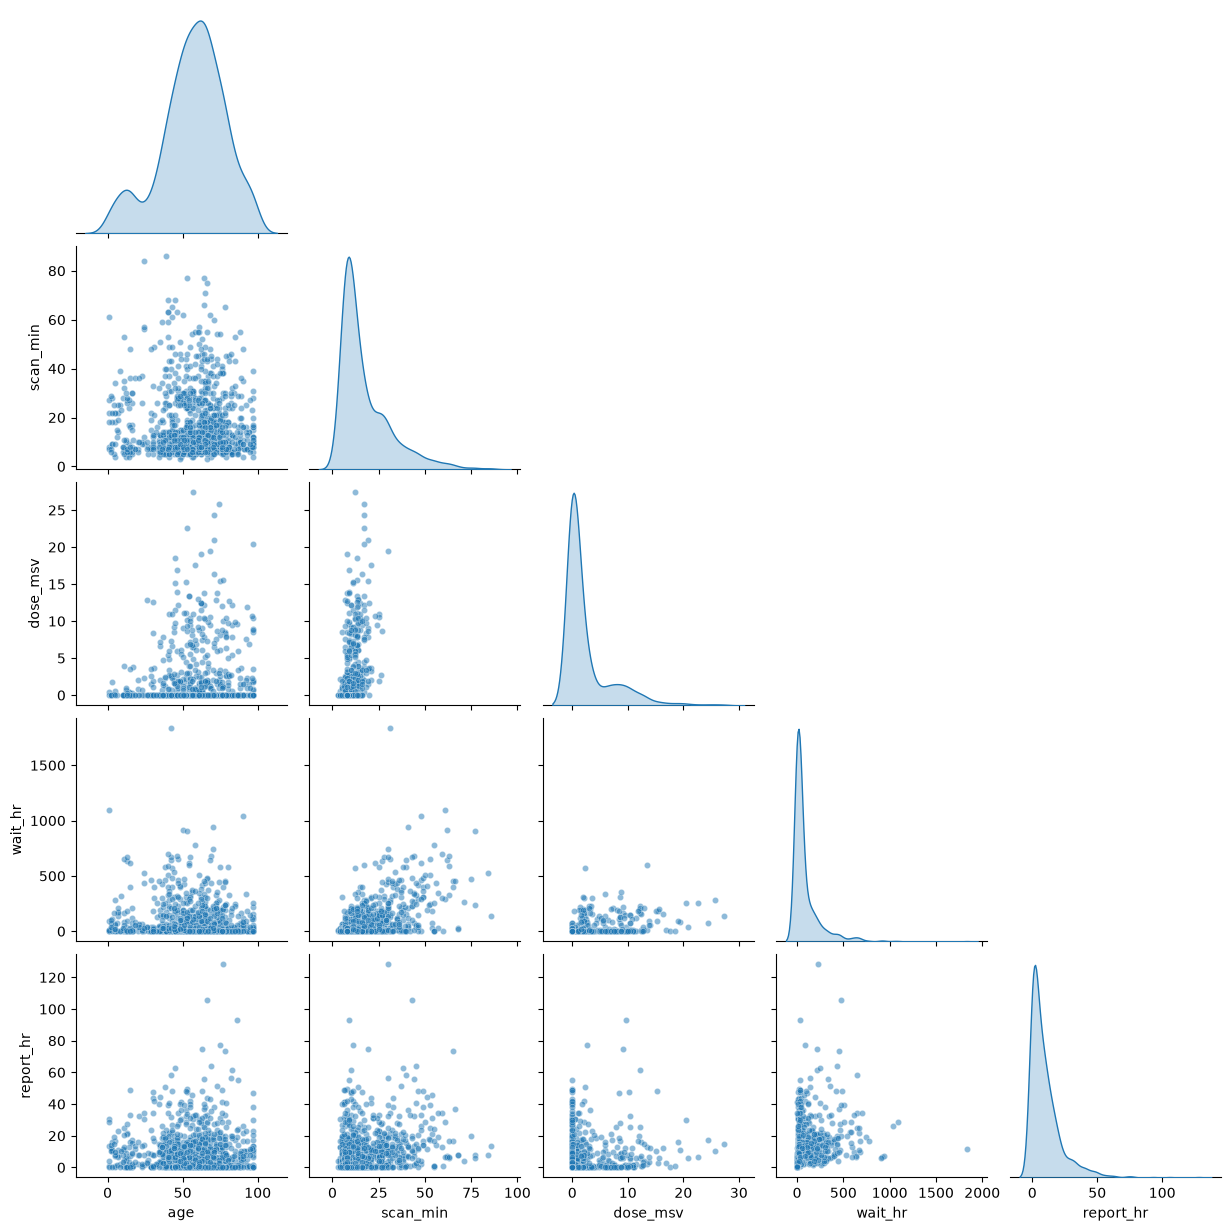

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
# Sample 1,000 exams with a fixed random state for reproducibility
numeric_cols = ["age", "scan_min", "dose_msv", "wait_hr", "report_hr"]
sample_exams = exams[numeric_cols].sample(n=1000, random_state=42)

pairplot_fig = sns.pairplot(sample_exams, corner=True, diag_kind="kde", plot_kws={"alpha": 0.5, "s": 20})
PAIRPLOT_PNG = Path("output/pairplot.png")
PAIRPLOT_PNG.parent.mkdir(parents=True, exist_ok=True)
pairplot_fig.savefig(PAIRPLOT_PNG, dpi=150, bbox_inches="tight")
plt.show()

In [5]:
MISSING_PATH = Path("output/missing_by_modality.csv")

# Calculate share of missing report_hr and dose_msv by modality
missing_by_modality = exams.groupby("modality").agg(
    report_hr=('report_hr', lambda x: x.isna().mean()),
    dose_msv=('dose_msv', lambda x: x.isna().mean())
)
missing_by_modality.to_csv(MISSING_PATH)
display(missing_by_modality)

# IQR fence for wait_hr
q1 = exams["wait_hr"].quantile(0.25)
q3 = exams["wait_hr"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
waits_above_fence = (exams["wait_hr"] > upper_fence).sum()

print(f"Quartiles: Q1 = {q1}, Q3 = {q3}")
print(f"Upper IQR fence: {upper_fence}")
print(f"Waits above fence: {waits_above_fence}")

,report_hr,dose_msv
modality,,
CT,0.003868,0.0
MRI,0.005355,1.0
Ultrasound,0.004148,1.0
X-ray,0.003993,0.0


Quartiles: Q1 = 1.5, Q3 = 96.1
Upper IQR fence: 237.99999999999997
Waits above fence: 55401


### 1.2 Put the sites in reporting order

This step saves nothing.

In [6]:
SITE_ORDER = [
    "Downtown", "Harbor", "Northgate",
    "Belmont", "Hillcrest", "Lakeside", "Metro", "Pinehurst", "Riverside", "Westfield", "Valley", "Eastport"
]
SITE_SUMMARY_PATH = Path("output/site_summary.csv")

exams["site"] = pd.Categorical(exams["site"], categories=SITE_ORDER, ordered=True)

### 1.3 Count exams, reports, and patients, and total the scanner time

> **Checkpoint: `output/site_summary.csv`**
> Eight rows under the header `site,exam_count,report_count,patient_count,total_scan_min,mean_scan_min`.

In [17]:
SITE_SUMMARY_PATH = Path("output/site_summary.csv")

# Group by site using observed=True to drop sites with zero exams
site_summary = (
    exams.groupby("site", observed=True)
    .agg(
        exam_count=("exam_id", "count"),
        report_count=("report_hr", "count"),  # count() skips NaNs automatically
        patient_count=("patient_id", "nunique"),
        total_scan_min=("scan_min", "sum"),
        mean_scan_min=("scan_min", "mean"),
    )
    .reset_index()
)

# Filter out any remaining rows with zero exams just to be sure
site_summary = site_summary[site_summary["exam_count"] > 0]

site_summary.to_csv(SITE_SUMMARY_PATH, index=False)
display(site_summary)
print("Total rows:", len(site_summary))

,site,exam_count,report_count,patient_count,total_scan_min,mean_scan_min
0,Downtown,129876,129366,60995,2239524,17.243555
1,Harbor,108818,108422,52764,1839569,16.905007
2,Northgate,120961,120484,61314,1999568,16.530683
3,Hillcrest,37883,37689,22516,767578,20.261806
4,Lakeside,44420,44206,26507,906052,20.397389
5,Riverside,35660,35487,21898,732561,20.542933
6,Westfield,37226,37032,23363,844368,22.682211
7,Valley,25384,25280,12905,359150,14.148676


Total rows: 8


## Task 2: Compare sites, modalities, and single exams

### 2.1 Summarize each site and modality

> **Checkpoint: `output/site_modality_summary.csv`**
> 31 rows under the header `site,modality,exam_count,median_wait_hr,median_report_hr`.

In [18]:
SITE_MODALITY_PATH = Path("output/site_modality_summary.csv")

# Group by site and modality using observed=True to drop unobserved pairs (e.g. Valley MRI)
site_modality = (
    exams.groupby(["site", "modality"], observed=True)
    .agg(
        exam_count=("exam_id", "count"),
        median_wait_hr=("wait_hr", "median"),
        median_report_hr=("report_hr", "median"),
    )
    .reset_index()
)

# Filter to keep only pairs that actually have exams (exam_count > 0)
site_modality = site_modality[site_modality["exam_count"] > 0]

site_modality.to_csv(SITE_MODALITY_PATH, index=False)
display(site_modality.head(10))
print("Total rows:", len(site_modality))

,site,modality,exam_count,median_wait_hr,median_report_hr
0,Downtown,CT,33864,2.4,1.610
1,Downtown,MRI,15687,269.0,13.190
2,Downtown,Ultrasound,26678,56.7,5.940
3,Downtown,X-ray,53647,5.5,3.080
4,Harbor,CT,29776,2.2,1.140
5,Harbor,MRI,12326,278.3,9.820
6,Harbor,Ultrasound,21573,51.2,4.250
7,Harbor,X-ray,45143,4.5,2.020
8,Northgate,CT,34188,1.6,1.110
9,Northgate,MRI,12900,227.5,10.865


Total rows: 31


### 2.2 Flag STAT exams that waited far longer than their peers

> **Checkpoint: `output/delayed_stat_exams.csv`**
> 190 rows under the header `exam_id,site,modality,wait_hr,peer_median_wait_hr,wait_vs_peer_hr`.

In [9]:
DELAYED_STAT_PATH = Path("output/delayed_stat_exams.csv")

# 1. Filter STAT exams and take a copy
stat = exams[exams["priority"] == "STAT"].copy()

# 2. Add peer median wait time grouped by site and modality using transform
stat["peer_median_wait_hr"] = stat.groupby(["site", "modality"], observed=False)["wait_hr"].transform("median")

# 3. Add wait difference vs peer median
stat["wait_vs_peer_hr"] = stat["wait_hr"] - stat["peer_median_wait_hr"]

# 4. Filter delayed STAT exams (waited strictly more than 8 hours)
delayed_stat = stat[stat["wait_hr"] > 8][
    ["exam_id", "site", "modality", "wait_hr", "peer_median_wait_hr", "wait_vs_peer_hr"]
].copy()

delayed_stat.to_csv(DELAYED_STAT_PATH, index=False)
print("Delayed STAT count:", len(delayed_stat))
display(delayed_stat.head())

Delayed STAT count: 190


,exam_id,site,modality,wait_hr,peer_median_wait_hr,wait_vs_peer_hr
382,E0000383,Northgate,Ultrasound,9.0,0.9,8.1
543,E0000544,Downtown,MRI,17.4,1.7,15.7
774,E0000775,Northgate,X-ray,8.3,0.4,7.9
4266,E0004267,Harbor,CT,10.5,0.7,9.8
4701,E0004702,Downtown,MRI,9.4,1.7,7.7


### 2.3 Build a CT radiation-dose review list

> **Checkpoint: `output/ct_dose_review.csv`**
> 1,253 rows under the header `exam_id,patient_id,dose_msv`.

In [10]:
CT_DOSE_PATH = Path("output/ct_dose_review.csv")

# 1. Filter CT exams
ct = exams[exams["modality"] == "CT"].copy()

# 2. Patient total dose filter using groupby + filter
dose_review = ct.groupby("patient_id", group_keys=False).filter(lambda g: g["dose_msv"].sum() >= 100)

# 4. Alternative fast review using transform (optional validation)
ct["patient_total_dose"] = ct.groupby("patient_id")["dose_msv"].transform("sum")
fast_review = ct[ct["patient_total_dose"] >= 100]

print("Filter rows:", len(dose_review), "| Fast review rows:", len(fast_review))

# 5. Save required columns
dose_review[["exam_id", "patient_id", "dose_msv"]].to_csv(CT_DOSE_PATH, index=False)
display(dose_review[["exam_id", "patient_id", "dose_msv"]].head())

Filter rows: 1253 | Fast review rows: 1253


,exam_id,patient_id,dose_msv
13,E0000014,P202445,1.981
138,E0000139,P010342,16.323
1117,E0001118,P152807,6.509
1213,E0001214,P097874,19.777
1399,E0001400,P074625,13.963


### 2.4 Pull each site's three slowest STAT reports

> **Checkpoint: `output/slowest_stat_reports.csv`**
> 24 rows under the header `exam_id,site,modality,report_hr`.

In [11]:
SLOWEST_PATH = Path("output/slowest_stat_reports.csv")

# 1. Group stat exams by site and keep 3 largest report_hr using apply and nlargest
slowest = (
    stat.groupby("site", observed=True)
    .apply(lambda g: g.nlargest(3, "report_hr"))
    .reset_index(level=1, drop=True)
    .reset_index()
)

# 2. Keep the four required columns
slowest_stat_reports = slowest[["exam_id", "site", "modality", "report_hr"]]
slowest_stat_reports.to_csv(SLOWEST_PATH, index=False)
display(slowest_stat_reports)

,exam_id,site,modality,report_hr
0,E0313443,Downtown,X-ray,14.82
1,E0183831,Downtown,MRI,14.27
2,E0046635,Downtown,X-ray,12.49
3,E0180229,Harbor,X-ray,7.33
4,E0015432,Harbor,CT,7.00
5,E0060006,Harbor,X-ray,6.89
6,E0082383,Northgate,X-ray,8.34
7,E0404764,Northgate,MRI,8.22
8,E0506694,Northgate,MRI,7.50
9,E0485699,Hillcrest,Ultrasound,6.91


## Task 3: Pivot the report times

### 3.1 Build the pivot table and check it

> **Checkpoint: `output/median_report_pivot.csv`**
> Eight rows, `Downtown` to `Valley`, under the header `site,CT,MRI,Ultrasound,X-ray`; Valley's `MRI` cell stays empty.

In [12]:
PIVOT_PATH = Path("output/median_report_pivot.csv")

# 1. Build pivot table of median report times
report_pivot = pd.pivot_table(
    exams,
    index="site",
    columns="modality",
    values="report_hr",
    aggfunc="median",
    observed=True
)

# 2. Build groupby twin with unstack
groupby_twin = exams.groupby(["site", "modality"], observed=True)["report_hr"].median().unstack()

print("Pivot matches groupby twin:", report_pivot.equals(groupby_twin))
print("Empty cells count:", report_pivot.isna().sum().sum())

# 3. Save with index
report_pivot.to_csv(PIVOT_PATH)
display(report_pivot)

Pivot matches groupby twin: True
Empty cells count: 1


modality,CT,MRI,Ultrasound,X-ray
site,,,,
Downtown,1.610,13.190,5.94,3.08
Harbor,1.140,9.820,4.25,2.02
Northgate,1.110,10.865,4.24,1.88
Hillcrest,10.685,14.605,9.59,8.38
Lakeside,10.710,14.570,9.29,8.19
Riverside,11.125,14.750,9.40,8.36
Westfield,10.750,14.580,9.30,8.42
Valley,2.020,NaN,7.12,4.56


### 3.2 Count the exams in each pair

This step saves nothing.

In [13]:
# Crosstab of exam counts by site and modality
exam_counts = pd.crosstab(exams["site"], exams["modality"])
display(exam_counts)

modality,CT,MRI,Ultrasound,X-ray
site,,,,
Downtown,33864,15687,26678,53647
Harbor,29776,12326,21573,45143
Northgate,34188,12900,23444,50429
Hillcrest,5812,7704,9655,14712
Lakeside,6744,9010,11504,17162
Riverside,5576,7179,9231,13674
Westfield,5034,10644,8665,12883
Valley,6992,0,6409,11983


## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [14]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  2/2  missing by modality: columns
[PASS]  2/2  missing by modality: one row per modality
[PASS]  4/4  missing by modality: shares
[PASS]  4/4  pairplot: saved chart
[PASS]  2/2  site summary: columns
[FIX ]  0/2  site summary: one row per site
         output/site_summary.csv also has a row for Belmont, a row for Metro and a row for Pinehurst; it should hold one row for each of Downtown, Harbor, Northgate, ... and Valley (8 in all). Fix it in Task 1.3: Group exams by "site": one row per site that has exams.
[PASS]  4/4  site summary: exam_count values
[PASS]  4/4  site summary: report_count values
[PASS]  4/4  site summary: patient_count values
[PASS]  4/4  site summary: total_scan_min values
[PASS]  4/4  site summary: mean_scan_min values
[PASS]  2/2  site and modality: columns
[PASS]  2/2  site and modality: one row per pair
[PASS]  4/4  site and modality: exam_count values
[PASS]  4/4  site and modality: median_wait_hr values